# Band occupancy and spurious-emission classification from ARGUS/ESMD sweep archives

Reproduces every figure and table of the paper *"A statistical computing pipeline for band occupancy and
spurious-emission classification from radio monitoring archives"* (ICASC 2026) from **one month of `.exp`
sweep exports**.

**Data layout** (as produced by the ARGUS sorting notebook): one folder per mission, one sub-folder per band,
`.exp` files (one per day):

```
<WORK_ROOT>\<mission>\<band>\00000abc.exp
```

ARGUS also writes an XML descriptor next to each `.exp` file. The pipeline does not need it: if present, it is only
copied into the `meta` field of the results. The sample data in this repository ship without descriptors.

For each station the pipeline needs one **band-III mission** (174–230 MHz, the band under study) and one
**FM-band mission** (87.5–108 MHz, the independent transmitter record used as ground truth).

**Repository layout** — `notebooks/` (this notebook), `src/` (the same decoder and pipeline as importable modules),
`data/2026.08/` (sample month: six missions of the three stations), `results/` (figures, tables, `results.json`).
Run the notebook from the `notebooks/` folder; it needs only NumPy, SciPy, pandas and Matplotlib (`requirements.txt`).

**Pipeline** — decode `.exp` → sweep matrix → level histogram (quantization-aware bins) → log-χ² noise model
and analytic $P_{fa}$ thresholds → noise ridge $r(f)$ and sweep floor $s(t)$ detrending → rule-based channel
classification (occupancy, margin, recurrence, FM arithmetic, co-activation) → occupancy under competing
threshold rules. All figures are saved as PDF + PNG in `OUT_DIR`.

In [1]:
# ╔══════════════════════════════════════════════════════╗
# ║ CELL 1 — CONFIGURATION                               ║
# ╚══════════════════════════════════════════════════════╝
import os

# Root folder holding the sorted missions of one month.
# Default: the sample dataset shipped in the repository (notebooks/ -> ../data/2026.08).
# On the monitoring PC use the full archive instead, e.g. WORK_ROOT = r'E:\SORTED_08\CRC5\2026.08'
WORK_ROOT = os.path.join('..', 'data', '2026.08')

# Stations: tag -> (band-III mission folder, FM mission folder, label used in figures)
STATIONS = {
    'R': ('rRD_02', 'rFM_04', 'Reșița (R)'),
    'K': ('KRd001', 'KFM001', 'Timișoara–Kathrein (K)'),
    'Y': ('Yrd_00', 'Yfm_01', 'Ianova (Y)'),
}
MAIN = 'R'                     # station used for the detailed figures (heatmaps, histograms, classification)

OUT_DIR   = os.path.join('..', 'results')                # where figures / tables / results are written
PFA       = 1e-3               # nominal false-alarm probability of the calibrated threshold
QUANT     = 0.1                # level quantum of the .exp export (dB)
TRUNC_DB  = 3.0                # noise-model fit uses histogram bins up to mode + TRUNC_DB
MARGIN_MAX = 15.0              # dB: above this median margin an active channel is a 'signal'
PROD_TOL  = 0.275              # MHz: FM-product tolerance = half channel step (0.125) + product deviation (0.150)
ART_JUMP  = 6.0                # dB: sweeps whose band floor jumps more than this are instrument artefacts
DPI_OUT   = 300

os.makedirs(OUT_DIR, exist_ok=True)
print('Output folder:', OUT_DIR)

Output folder: ../results


## 2. `.exp` decoder and sweep matrix
Record = FILETIME (uint64) | frequency Hz (float64) | level dBµV/m (float64) | pad (uint16), 26 bytes, little endian. The header length varies, so the data block is found by searching for six consecutive plausible FILETIME values at the record stride.

In [2]:
# ╔══════════════════════════════════════════════════════╗
# ║ CELL 2 — DECODER (.exp → arrays → sweep matrix)      ║
# ╚══════════════════════════════════════════════════════╝
import glob, os, re, struct, datetime
import numpy as np

REC = 26
DT = np.dtype([('ft', '<u8'), ('freq', '<f8'), ('level', '<f8'), ('pad', '<u2')])
EPOCH = datetime.datetime(1601, 1, 1)
FT_LO = int((datetime.datetime(2000, 1, 1) - EPOCH).total_seconds() * 1e7)
FT_HI = int((datetime.datetime(2100, 1, 1) - EPOCH).total_seconds() * 1e7)


def find_data_start(data, search_limit=300000, confirm=6):
    limit = min(search_limit, len(data) - 8)
    for i in range(0, limit, 2):
        v = struct.unpack_from('<Q', data, i)[0]
        if FT_LO <= v <= FT_HI:
            ok = True
            for k in range(1, confirm):
                off = i + k * REC
                if off + 8 > len(data):
                    ok = False; break
                v2 = struct.unpack_from('<Q', data, off)[0]
                if not (FT_LO <= v2 <= FT_HI):
                    ok = False; break
            if ok:
                return i
    return None


def decode_exp(path):
    data = open(path, 'rb').read()
    start = find_data_start(data)
    if start is None:
        return np.empty(0), np.empty(0), np.empty(0, dtype=np.uint64)
    n = (len(data) - start) // REC
    arr = np.frombuffer(data[start:start + n * REC], dtype=DT, count=n)
    f = arr['freq'] / 1e6
    L = arr['level']
    ok = (f > 1) & (f < 6000) & (L > -200) & (L < 200)
    return f[ok], L[ok], arr['ft'][ok]


def ft_to_datetime64(ft):
    us = (ft // 10).astype('int64')
    return np.datetime64('1601-01-01T00:00:00', 'us') + us.astype('timedelta64[us]')


def parse_xml(path):
    txt = open(path, encoding='utf-8-sig', errors='ignore').read()
    def g(p, cast=str):
        m = re.search(p, txt)
        return cast(m.group(1).strip()) if m else None
    return dict(
        station=g(r'<MD_S_NAME>([^<]*)'),
        fmin=g(r'Minimum Frequency:\s*([\d.]+)', float),
        fmax=g(r'Maximum Frequency:\s*([\d.]+)', float),
        step_khz=g(r'Step Width:\s*([\d.]+)', float),
        detector=g(r'Detector:\s*([^\r\n<]+)'),
        ifbw=g(r'IF Bandwidth:\s*([^\r\n<]+)'),
        antenna=g(r'<MD_M_ANT>([^<]*)'),
        receiver=g(r'<MD_M_REC>([^<]*)'),
        start=g(r'<MD_M_START>([^<]*)'),
        stop=g(r'<MD_M_STOP>([^<]*)'),
    )


def load_mission(folder, max_files=None):
    """Load all .exp files of one band folder -> dict with concatenated arrays."""
    files = sorted(glob.glob(os.path.join(folder, '*.exp')))
    if max_files:
        files = files[:max_files]
    F, L, T = [], [], []
    for p in files:
        f, l, t = decode_exp(p)
        F.append(f); L.append(l); T.append(t)
    f = np.concatenate(F); L = np.concatenate(L); t = np.concatenate(T)
    xmls = glob.glob(os.path.join(folder, '*.xml'))
    meta = parse_xml(xmls[0]) if xmls else {}
    return dict(freq=f, level=L, ft=t, files=files, meta=meta)


def sweep_matrix(f, L, t, decimals=5):
    """Arrange records into a (n_sweeps x n_channels) matrix using sweep
    boundaries detected as frequency wrap-around. Returns (uf, M, t_sweep)."""
    fr = np.round(f, decimals)
    uf = np.unique(fr)
    idx = np.searchsorted(uf, fr)
    # sweep boundaries: frequency decreases
    brk = np.flatnonzero(np.diff(fr) < 0) + 1
    starts = np.concatenate([[0], brk])
    ends = np.concatenate([brk, [len(fr)]])
    M = np.full((len(starts), len(uf)), np.nan)
    ts = np.empty(len(starts), dtype='datetime64[us]')
    dt = ft_to_datetime64(t)
    for k, (s, e) in enumerate(zip(starts, ends)):
        M[k, idx[s:e]] = L[s:e]
        ts[k] = dt[s]
    return uf, M, ts

print('Decoder loaded.')

Decoder loaded.


## 3. Statistical functions
Quantization-aware histogram, log-χ² (log-gamma) noise model with analytic thresholds, competing models and goodness of fit, noise ridge, FM transmitter extraction, classification rules and co-activation.

In [3]:
# ╔══════════════════════════════════════════════════════╗
# ║ CELL 3 — STATISTICAL PIPELINE FUNCTIONS               ║
# ╚══════════════════════════════════════════════════════╝
import numpy as np
from scipy import special, optimize, stats, ndimage

LN10_10 = np.log(10.0) / 10.0


# ----------------------------------------------------------------- binning
def fd_bin_width(x):
    """Freedman–Diaconis width."""
    q75, q25 = np.percentile(x, [75, 25])
    return 2.0 * (q75 - q25) * x.size ** (-1.0 / 3.0)


def quantized_bin_width(x, q=QUANT, rule='fd'):
    """Bin width: an integer multiple of the level quantum q, never below q,
    rounded from the Freedman–Diaconis (or Scott) width."""
    if rule == 'scott':
        w = 3.49 * np.std(x) * x.size ** (-1.0 / 3.0)
    else:
        w = fd_bin_width(x)
    return q * max(1, int(round(w / q)))


def histogram_q(x, w, q=QUANT, lo=None, hi=None):
    """Histogram with edges aligned on the quantum grid (edges at k*w - q/2)."""
    lo = np.floor((x.min() if lo is None else lo) / w) * w - q / 2
    hi = np.ceil((x.max() if hi is None else hi) / w) * w + w
    edges = np.arange(lo, hi + w / 2, w)
    cnt, _ = np.histogram(x, bins=edges)
    ctr = 0.5 * (edges[:-1] + edges[1:])
    return ctr, cnt, edges


def hist_mode(x, w=None):
    if w is None:
        w = quantized_bin_width(x)
    ctr, cnt, _ = histogram_q(x, w)
    return ctr[np.argmax(cnt)], w


# --------------------------------------------------- log-gamma noise model
# x = 10 log10 P, P ~ Gamma(k, theta).  Parametrised by (mu, k) with
# mu = 10 log10(k theta) = mode of x.
def lg_logpdf(x, mu, k):
    z = k * 10 ** ((x - mu) / 10.0)          # P/theta
    return np.log(LN10_10) + k * np.log(z) - z - special.gammaln(k)


def lg_cdf(x, mu, k):
    z = k * 10 ** ((x - mu) / 10.0)
    return special.gammainc(k, z)


def lg_sf(x, mu, k):
    z = k * 10 ** ((x - mu) / 10.0)
    return special.gammaincc(k, z)


def lg_threshold(mu, k, pfa):
    """Analytic threshold: P(x > T) = pfa."""
    z = special.gammainccinv(k, pfa)
    return mu + 10 * np.log10(z / k)


def lg_sigma(k):
    """Std of x in dB: 10/ln10 * sqrt(trigamma(k))."""
    return (10 / np.log(10)) * np.sqrt(special.polygamma(1, k))


def _binned_trunc_nll(params, ctr, cnt, w, xt, logpdf, cdf):
    """Poisson NLL of binned data truncated at xt (bins with centre <= xt)."""
    m = ctr <= xt
    # bin probabilities via cdf differences
    lo = ctr[m] - w / 2; hi = ctr[m] + w / 2
    p = cdf(hi, *params) - cdf(lo, *params)
    p = np.clip(p, 1e-300, None)
    p /= cdf(xt + w / 2, *params)
    n = cnt[m].sum()
    return -(cnt[m] * np.log(p)).sum() + n * np.log(1.0)  # multinomial


def fit_loggamma(x, trunc_above_mode=3.0, w=None):
    """Truncated ML fit of the log-gamma model on the histogram of x,
    using only bins up to (mode + trunc_above_mode) dB so that the signal
    tail does not bias the noise fit. Returns dict."""
    if w is None:
        w = quantized_bin_width(x)
    ctr, cnt, edges = histogram_q(x, w)
    mu0 = ctr[np.argmax(cnt)]
    xt = mu0 + trunc_above_mode
    lo_half = x[x <= mu0]
    s0 = max(0.3, np.sqrt(np.mean((lo_half - mu0) ** 2)))
    k0 = max(1.5, (4.343 / s0) ** 2)

    def nll(p):
        mu, lk = p
        return _binned_trunc_nll((mu, np.exp(lk)), ctr, cnt, w, xt, lg_logpdf, lg_cdf)
    res = optimize.minimize(nll, [mu0, np.log(k0)], method='Nelder-Mead',
                            options=dict(xatol=1e-4, fatol=1e-3, maxiter=2000))
    mu, k = res.x[0], float(np.exp(res.x[1]))
    return dict(mu=mu, k=k, w=w, mode_hist=mu0, xt=xt, ctr=ctr, cnt=cnt,
                sigma=lg_sigma(k), nll=res.fun, n_used=int(cnt[ctr <= xt].sum()))


# --- competing models (same truncated binned ML) -------------------------
def gauss_cdf(x, mu, s):
    return stats.norm.cdf(x, mu, s)


def gumbel_cdf(x, mu, b):
    # Gumbel (min) — the k=1 log-exponential limit has this shape
    return 1 - np.exp(-np.exp((x - mu) / b))


def fit_model(x, cdf, p0, trunc_above_mode=3.0, w=None):
    if w is None:
        w = quantized_bin_width(x)
    ctr, cnt, edges = histogram_q(x, w)
    mu0 = ctr[np.argmax(cnt)]
    xt = mu0 + trunc_above_mode

    def nll(p):
        if p[1] <= 0:
            return 1e300
        return _binned_trunc_nll(tuple(p), ctr, cnt, w, xt, None, cdf)
    res = optimize.minimize(nll, p0, method='Nelder-Mead',
                            options=dict(xatol=1e-4, fatol=1e-3, maxiter=2000))
    return dict(params=res.x, nll=res.fun, w=w, ctr=ctr, cnt=cnt, xt=xt)


def gof_stats(ctr, cnt, w, xt, cdf, params, n_par):
    """Chi-square/dof and KS distance on the truncated (noise) region."""
    m = ctr <= xt
    lo = ctr[m] - w / 2; hi = ctr[m] + w / 2
    p = cdf(hi, *params) - cdf(lo, *params)
    p = p / cdf(xt + w / 2, *params)
    n = cnt[m].sum()
    exp = n * p
    ok = exp > 5
    chi2 = ((cnt[m][ok] - exp[ok]) ** 2 / exp[ok]).sum()
    dof = ok.sum() - n_par - 1
    F_emp = np.cumsum(cnt[m]) / n
    F_mod = np.cumsum(p)
    ks = np.max(np.abs(F_emp - F_mod))
    return chi2 / max(dof, 1), ks, int(n)


# ---------------------------------------------------------- detrending
def channel_modes(M, w):
    """Histogram-max level of each column of the sweep matrix M."""
    modes = np.full(M.shape[1], np.nan)
    for j in range(M.shape[1]):
        c = M[:, j]; c = c[np.isfinite(c)]
        if c.size < 10:
            continue
        ctr, cnt, _ = histogram_q(c, w)
        modes[j] = ctr[np.argmax(cnt)]
    return modes


def noise_ridge(uf, modes, win=9, excl_db=3.0):
    """Interpolate the noise-band tilt through the column modes, excluding
    columns whose mode stands out from a running-median baseline (signal-
    dominated columns). Returns ridge (same length as uf) and mask of
    columns used."""
    base = ndimage.median_filter(modes, size=win, mode='nearest')
    good = np.isfinite(modes) & (modes - base <= excl_db)
    ridge = np.interp(uf, uf[good], modes[good])
    # light smoothing (3-point) to remove residual quantization steps
    ridge = ndimage.uniform_filter1d(ridge, 3, mode='nearest')
    return ridge, good


# ---------------------------------------------------------- classification
def fm_transmitters(uf, M, margin_db=20.0):
    """Identify transmitter centre frequencies in an FM-band sweep record:
    channels whose median level exceeds the band floor (20th percentile of
    channel medians) by margin_db, grouped into contiguous runs; centre =
    argmax of median within run."""
    med = np.nanmedian(M, 0)
    floor = np.percentile(med[np.isfinite(med)], 20)
    hot = med > floor + margin_db
    tx = []
    j = 0
    while j < len(uf):
        if hot[j]:
            k = j
            while k + 1 < len(uf) and hot[k + 1]:
                k += 1
            seg = slice(j, k + 1)
            jj = j + int(np.argmax(med[seg]))
            tx.append((uf[jj], med[jj]))
            j = k + 1
        else:
            j += 1
    return tx, floor


def arithmetic_matches(f, fm_list, tol):
    """Return list of (label) explanations of f as 2*fi or fi+fj."""
    out = []
    for fi in fm_list:
        if abs(f - 2 * fi) <= tol:
            out.append(f'2x{fi:.1f}')
    n = len(fm_list)
    for a in range(n):
        for b in range(a + 1, n):
            if abs(f - (fm_list[a] + fm_list[b])) <= tol:
                out.append(f'{fm_list[a]:.1f}+{fm_list[b]:.1f}')
    return out


def classify_channels(uf, D, ts, T, pfa, fm_list, tol, margin_max=15.0,
                      occ_cont=0.9, min_days_frac=0.5):
    """Rule set on the detrended sweep matrix D (levels relative to local
    floor) with threshold offset T. Returns list of dicts per channel."""
    n_sw = D.shape[0]
    days = ts.astype('datetime64[D]')
    uday = np.unique(days)
    A = D > T                                   # activity matrix
    occ = A.mean(0)
    # binomial upper bound of false-alarm occupancy
    occ_fa = pfa + 4 * np.sqrt(pfa * (1 - pfa) / n_sw)
    rows = []
    for j, f in enumerate(uf):
        a = A[:, j]
        act = occ[j] > occ_fa
        # days with activity above the false-alarm expectation
        nd = 0
        for d in uday:
            m = days == d
            if m.sum() and a[m].mean() > pfa + 4 * np.sqrt(pfa * (1 - pfa) / m.sum()):
                nd += 1
        exc = D[a, j]
        margin = float(np.median(exc)) if exc.size else 0.0
        p95 = float(np.percentile(exc, 95)) if exc.size else 0.0
        matches = arithmetic_matches(f, fm_list, tol)
        if not act:
            cls = 'noise'
        elif occ[j] >= occ_cont:
            cls = 'continuous'
        elif margin <= margin_max and nd >= min_days_frac * len(uday):
            cls = 'spurious'
        elif margin <= margin_max:
            cls = 'weak-sporadic'
        else:
            cls = 'signal'
        rows.append(dict(f=f, occ=occ[j], active=act, days=nd, ndays=len(uday),
                         margin=margin, p95=p95, cls=cls, matches=matches))
    return rows, A, occ_fa


def coactivation(A, idx):
    """Mean pairwise phi coefficient among columns idx of activity matrix A."""
    X = A[:, idx].astype(float)
    if X.shape[1] < 2:
        return np.nan, None
    C = np.corrcoef(X.T)
    iu = np.triu_indices(len(idx), 1)
    return float(np.nanmean(C[iu])), C

print('Pipeline functions loaded.')

Pipeline functions loaded.


## 4. Run the pipeline for every station
Each run returns all numbers used in the paper (`res[tag]`) and the arrays needed for the figures (`arr[tag]`).

In [4]:
# ╔══════════════════════════════════════════════════════╗
# ║ CELL 4 — ANALYSIS (one call per station)              ║
# ╚══════════════════════════════════════════════════════╝
import json, glob, time
import pandas as pd
from scipy.stats import hypergeom

def fwhm(ctr, cnt):
    pk = cnt.argmax(); h = cnt[pk] / 2; l = pk
    while l > 0 and cnt[l] > h: l -= 1
    r = pk
    while r < len(cnt) - 1 and cnt[r] > h: r += 1
    return float(ctr[r] - ctr[l])

def gof_table(x, w, fit):
    """KS distance and reduced chi-square of the four candidate models on the truncated region."""
    k1cdf = lambda v, mu, d: lg_cdf(v, mu, 1.0)
    out = {'log-chi2': gof_stats(fit['ctr'], fit['cnt'], w, fit['xt'], lg_cdf, (fit['mu'], fit['k']), 2)}
    for name, cdf, npar in [('Gaussian', gauss_cdf, 2), ('Gumbel', gumbel_cdf, 2), ('log-exponential', k1cdf, 1)]:
        r = fit_model(x, cdf, [fit['mode_hist'], 1.0], w=w)
        out[name] = gof_stats(r['ctr'], r['cnt'], w, r['xt'], cdf, tuple(r['params']), npar)
    return {k: dict(chi2_dof=float(v[0]), KS=float(v[1]), n=int(v[2])) for k, v in out.items()}

def analyse_station(dab_folder, fm_folder, tag):
    OUT = {'tag': tag}
    t0 = time.time()
    b = load_mission(glob.glob(os.path.join(dab_folder, '*' + os.sep))[0])
    uf, M, ts = sweep_matrix(b['freq'], b['level'], b['ft'])
    OUT['decode_s'] = time.time() - t0
    M[M <= 0] = np.nan                                   # level 0.0 = invalid record
    OUT['meta'] = b['meta']; OUT['n_files'] = len(b['files']); OUT['n_records'] = int(b['freq'].size)
    OUT['n_channels'] = int(len(uf)); OUT['n_sweeps_raw'] = int(M.shape[0])
    t = pd.DatetimeIndex(ts)
    OUT['sweep_period_median_s'] = float(np.median(np.diff(ts).astype('timedelta64[s]').astype(float)))

    # ---- 1. raw band histogram and noise model
    L = M[np.isfinite(M)]
    w = quantized_bin_width(L)
    fit = fit_loggamma(L, TRUNC_DB, w=w)
    OUT['raw'] = dict(w=float(w), fd_width=float(fd_bin_width(L)), mode=float(fit['mode_hist']), mean=float(L.mean()),
                      median=float(np.median(L)), mu=float(fit['mu']), k=float(fit['k']), sigma=float(fit['sigma']),
                      T={str(p): float(lg_threshold(fit['mu'], fit['k'], p)) for p in [1e-2, 1e-3, 1e-4]},
                      gof=gof_table(L, w, fit), fwhm=fwhm(fit['ctr'], fit['cnt']))

    # ---- 2. noise ridge (frequency) and artefact sweeps
    modes = channel_modes(M, w)
    ridge, good = noise_ridge(uf, modes)
    OUT['ridge'] = dict(min=float(ridge.min()), max=float(ridge.max()), n_excluded=int((~good).sum()),
                        excluded=[float(f) for f in uf[~good]], modes_min=float(np.nanmin(modes)), modes_max=float(np.nanmax(modes)))
    D = M - ridge[None, :]
    sf = np.nanmedian(D[:, good], 1)
    art = sf > ART_JUMP
    OUT['artefact_sweeps'] = int(art.sum())
    keep = ~art
    M, D, ts, t, sf = M[keep], D[keep], ts[keep], t[keep], sf[keep]
    OUT['n_sweeps'] = int(M.shape[0]); OUT['n_days'] = int(len(np.unique(t.date)))
    Ld = D[np.isfinite(D)]
    wd = quantized_bin_width(Ld)
    fd = fit_loggamma(Ld, TRUNC_DB, w=wd)
    OUT['detr'] = dict(w=float(wd), mode=float(fd['mode_hist']), mu=float(fd['mu']), k=float(fd['k']), sigma=float(fd['sigma']),
                       fwhm=fwhm(fd['ctr'], fd['cnt']), T={str(p): float(lg_threshold(fd['mu'], fd['k'], p)) for p in [1e-2, 1e-3, 1e-4]},
                       gof=gof_table(Ld, wd, fd))

    # ---- 3. sweep-wise floor (time) and doubly detrended level E
    hrs = t.hour
    OUT['floor_by_hour'] = [float(np.median(sf[hrs == h])) if (hrs == h).any() else np.nan for h in range(24)]
    E = D - sf[:, None]
    Le = E[:, good]; Le = Le[np.isfinite(Le)]
    we = quantized_bin_width(Le)
    fe = fit_loggamma(Le, TRUNC_DB, w=we)
    T = lg_threshold(fe['mu'], fe['k'], PFA)
    OUT['E'] = dict(w=float(we), mu=float(fe['mu']), k=float(fe['k']), sigma=float(fe['sigma']), T_used=float(T),
                    T={str(p): float(lg_threshold(fe['mu'], fe['k'], p)) for p in [1e-2, 1e-3, 1e-4]},
                    tail={str(p): float(np.mean(Le > lg_threshold(fe['mu'], fe['k'], p))) for p in [1e-2, 1e-3, 1e-4]},
                    quantiles={str(q): float(np.percentile(Le, q)) for q in [90, 99, 99.9]})
    for nm, m in [('night', hrs <= 5), ('day', (hrs >= 9) & (hrs <= 16))]:
        x = E[m][:, good]; x = x[np.isfinite(x)]
        OUT['E']['tail_' + nm] = {str(p): float(np.mean(x > lg_threshold(fe['mu'], fe['k'], p))) for p in [1e-2, 1e-3]}

    # ---- 4. split-half validation
    odd = np.arange(E.shape[0]) % 2 == 1
    OUT['splithalf'] = {}
    for nm, trn, tst in [('odd->even', odd, ~odd), ('even->odd', ~odd, odd)]:
        x = E[trn][:, good]; x = x[np.isfinite(x)]; y = E[tst][:, good]; y = y[np.isfinite(y)]
        f_ = fit_loggamma(x, TRUNC_DB, w=we); q = np.percentile(x, 99)
        OUT['splithalf'][nm] = dict(k=float(f_['k']), T=float(lg_threshold(f_['mu'], f_['k'], PFA)),
                                    exceed=float(np.mean(y > lg_threshold(f_['mu'], f_['k'], PFA))),
                                    emp99_T=float(q), emp99_exceed=float(np.mean(y > q)))

    # ---- 5. FM transmitters from the FM-band record
    bf = load_mission(glob.glob(os.path.join(fm_folder, '*' + os.sep))[0])
    uff, Mf, tsf = sweep_matrix(bf['freq'], bf['level'], bf['ft'])
    Mf[Mf <= 0] = np.nan
    tx, ffloor = fm_transmitters(uff, Mf, margin_db=20.0)
    OUT['fm'] = dict(floor=float(ffloor), n_sweeps=int(Mf.shape[0]), n_channels=int(len(uff)),
                     tx20=[(float(f), float(l)) for f, l in tx], tx35=[(float(f), float(l)) for f, l in tx if l > ffloor + 35])
    fm_list = [f for f, l in tx]

    # ---- 6. classification
    rows, A, occ_fa = classify_channels(uf, E, ts, T, PFA, fm_list, PROD_TOL, margin_max=MARGIN_MAX)
    occ = np.array([r['occ'] for r in rows]); bg = occ[good]
    mad = 1.4826 * np.median(np.abs(bg - np.median(bg)))
    thr_act = np.median(bg) + 5 * mad
    OUT['occ_bg'] = dict(median=float(np.median(bg)), mad=float(mad), activity_bound=float(thr_act))
    for r in rows:
        r['active_bg'] = bool(r['occ'] > thr_act)
        r['cls2'] = ('background' if not r['active_bg'] else 'FM product' if r['matches'] else
                     'signal' if r['margin'] > MARGIN_MAX else 'recurrent low-margin')
    flag = [r for r in rows if r['active_bg']]
    OUT['flagged'] = [dict(f=float(r['f']), occ=float(r['occ']), margin=float(r['margin']), p95=float(r['p95']),
                           days=int(r['days']), matches=r['matches'], cls=r['cls2']) for r in flag]
    OUT['classes'] = {c: sum(1 for r in rows if r['cls2'] == c) for c in set(r['cls2'] for r in rows)}
    # chance level of the FM-arithmetic explanation (hypergeometric test)
    def products(fl):
        pr = set()
        for i, fi in enumerate(fl):
            if uf[0] <= 2 * fi <= uf[-1]: pr.add(round(2 * fi, 2))
            for fj in fl[i + 1:]:
                if uf[0] <= fi + fj <= uf[-1]: pr.add(round(fi + fj, 2))
        return pr
    def touched(pr, tol):
        tc = set()
        for p in pr:
            for j in np.flatnonzero(abs(uf - p) <= tol): tc.add(float(uf[j]))
        return tc
    pr = products(fm_list)
    OUT['arith'] = {}
    for nm, tol in [('physical', PROD_TOL), ('strict', 0.125)]:
        tc = touched(pr, tol); nm_act = sum(1 for r in flag if r['f'] in tc)
        OUT['arith'][nm] = dict(n_products=len(pr), n_touched=len(tc), frac_touched=len(tc) / len(uf), n_matched=nm_act,
                                p=float(hypergeom.sf(nm_act - 1, len(uf), len(tc), len(flag))) if flag else None)
    # co-activation of hourly median levels: FM-product channels vs. clean channels
    hour_id = t.values.astype('datetime64[h]'); uh = np.unique(hour_id)
    def hourly_median(j): return np.array([np.nanmedian(E[hour_id == h, j]) for h in uh])   # levels above the instantaneous floor
    def mean_corr(H):
        if H.ndim < 2 or H.shape[0] < 2: return None
        C = np.corrcoef(H); iu = np.triu_indices(H.shape[0], 1); return float(np.nanmean(C[iu]))
    idx_fm = [int(np.argmin(abs(uf - r['f']))) for r in flag if r['matches']]
    idx_clean = list(np.flatnonzero(good)[::7])[:max(len(idx_fm), 5)]
    OUT['coact'] = dict(fm_products=mean_corr(np.array([hourly_median(j) for j in idx_fm])) if idx_fm else None,
                        clean=mean_corr(np.array([hourly_median(j) for j in idx_clean])), n_fm=len(idx_fm))

    # ---- 7. occupancy under competing threshold rules
    OUT['occupancy_rules'] = {
        'fixed squelch 40 dBµV/m':            float(np.nanmean(M > 40)),
        'band mean + 10 dB':                  float(np.nanmean(M > OUT['raw']['mean'] + 10)),
        'band mode + 10 dB':                  float(np.nanmean(M > OUT['raw']['mode'] + 10)),
        'band mode + 6 dB':                   float(np.nanmean(M > OUT['raw']['mode'] + 6)),
        'log-chi2 T(1e-3), raw band':         float(np.nanmean(M > OUT['raw']['T']['0.001'])),
        'log-chi2 T(1e-3), ridge-detrended':  float(np.nanmean(D > OUT['detr']['T']['0.001'])),
        'log-chi2 T(1e-3), ridge + floor':    float(np.nanmean(E > T)),
        'empirical 99th pct, ridge + floor':  float(np.nanmean(E > OUT['E']['quantiles']['99'])),
    }
    arrays = dict(uf=uf, M=M, D=D, E=E, ts=ts, ridge=ridge, good=good, modes=modes, sf=sf, A=A, uff=uff, Mf=Mf, occ=occ, hour_id=hour_id, uh=uh)
    return OUT, arrays

res, arr = {}, {}
for tag, (dab, fm, label) in list(STATIONS.items()):
    if not (os.path.isdir(os.path.join(WORK_ROOT, dab)) and os.path.isdir(os.path.join(WORK_ROOT, fm))):
        print(f'--- {tag}: mission folder missing, skipped'); STATIONS.pop(tag); continue
    print(f'--- {tag}: {dab} + {fm}')
    res[tag], arr[tag] = analyse_station(os.path.join(WORK_ROOT, dab), os.path.join(WORK_ROOT, fm), tag)
    r = res[tag]
    print(f"    {r['n_records']:,} records, {r['n_channels']} channels, {r['n_sweeps_raw']} sweeps "
          f"({r['artefact_sweeps']} artefact sweeps removed), decode+matrix {r['decode_s']:.2f} s")
    print(f"    raw mode {r['raw']['mode']:.1f} / mean {r['raw']['mean']:.1f} dBµV/m; k={r['raw']['k']:.1f}; "
          f"detrended k={r['E']['k']:.1f}, T(Pfa={PFA:g}) = {r['E']['T_used']:.2f} dB above local floor; "
          f"realised exceedance {100*r['E']['tail'][str(PFA)]:.1f} %")
    print(f"    FM transmitters: {len(r['fm']['tx20'])} (>=20 dB), {len(r['fm']['tx35'])} (>=35 dB); "
          f"flagged {len(r['flagged'])} channels, classes {r['classes']}")
json.dump(res, open(os.path.join(OUT_DIR, 'results.json'), 'w'), indent=1, default=str)

--- R: rRD_02 + rFM_04


    6,989,405 records, 225 channels, 31064 sweeps (233 artefact sweeps removed), decode+matrix 1.05 s
    raw mode 30.2 / mean 31.8 dBµV/m; k=5.0; detrended k=7.1, T(Pfa=0.001) = 4.09 dB above local floor; realised exceedance 10.4 %
    FM transmitters: 15 (>=20 dB), 13 (>=35 dB); flagged 27 channels, classes {'recurrent low-margin': 2, 'FM product': 25, 'background': 198}
--- K: KRd001 + KFM001


    134,550 records, 225 channels, 598 sweeps (12 artefact sweeps removed), decode+matrix 0.31 s
    raw mode 44.2 / mean 45.1 dBµV/m; k=20.7; detrended k=18.4, T(Pfa=0.001) = 2.74 dB above local floor; realised exceedance 7.9 %
    FM transmitters: 18 (>=20 dB), 9 (>=35 dB); flagged 0 channels, classes {'background': 225}
--- Y: Yrd_00 + Yfm_01


    84,149 records, 225 channels, 374 sweeps (0 artefact sweeps removed), decode+matrix 0.31 s
    raw mode 45.2 / mean 45.3 dBµV/m; k=22.1; detrended k=26.3, T(Pfa=0.001) = 2.34 dB above local floor; realised exceedance 1.2 %
    FM transmitters: 13 (>=20 dB), 1 (>=35 dB); flagged 8 channels, classes {'recurrent low-margin': 8, 'background': 217}


## 5. Table I — missions used

In [5]:
rows = []
for tag, (dab, fm, label) in STATIONS.items():
    r = res[tag]
    rows.append(dict(station=tag, band='band III', mission=dab, channels=r['n_channels'], sweeps=r['n_sweeps_raw'],
                     period_s=r['sweep_period_median_s'], samples_M=r['n_records'] / 1e6))
    rows.append(dict(station=tag, band='FM', mission=fm, channels=r['fm']['n_channels'], sweeps=r['fm']['n_sweeps'],
                     period_s=np.nan, samples_M=r['fm']['n_sweeps'] * r['fm']['n_channels'] / 1e6))
tab1 = pd.DataFrame(rows); tab1.to_csv(os.path.join(OUT_DIR, 'table1_missions.csv'), index=False); tab1

,station,band,mission,channels,sweeps,period_s,samples_M
0,R,band III,rRD_02,225,31064,12.0,6.989405
1,R,FM,rFM_04,207,696,NaN,0.144072
2,K,band III,KRd001,225,598,3599.0,0.134550
3,K,FM,KFM001,207,577,NaN,0.119439
4,Y,band III,Yrd_00,225,374,3599.0,0.084149
5,Y,FM,Yfm_01,301,374,NaN,0.112574


## 6. Figure style

In [6]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.gridspec import GridSpec
plt.rcParams.update({'font.size': 7.5, 'font.family': 'serif', 'font.serif': ['Times New Roman', 'Nimbus Roman', 'DejaVu Serif'],
                     'axes.linewidth': 0.6, 'legend.fontsize': 6.5, 'axes.labelsize': 7.5, 'axes.titlesize': 8,
                     'lines.linewidth': 1.0, 'mathtext.fontset': 'stix', 'figure.dpi': 110, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.02})
COL = 3.45                       # IEEE column width (inch)
C = dict(blue='#1f5fa8', orange='#d9822b', green='#2e8b57', red='#c0392b', purple='#6a4c93', gray='#6b6b6b', teal='#128a8a')

def save(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name + '.pdf'))
    fig.savefig(os.path.join(OUT_DIR, name + '.png'), dpi=DPI_OUT)
    print('saved', name)

R = res[MAIN]; Z = arr[MAIN]
uf, M, D, E, ts, ridge, good, modes, sf, A, uff, Mf, occ = [Z[k] for k in ['uf','M','D','E','ts','ridge','good','modes','sf','A','uff','Mf','occ']]
t = pd.DatetimeIndex(ts)

## 7. Fig. 2 — frequency × level occurrence heatmap (raw with noise ridge); supplementary: detrended heatmap with threshold and flagged channels (not in the conference paper)

saved fig2_heatmap_raw


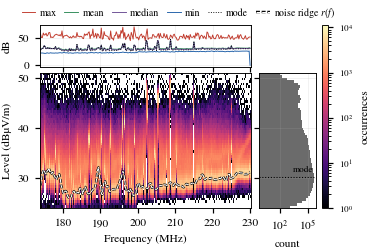

saved supp_heatmap_detrended


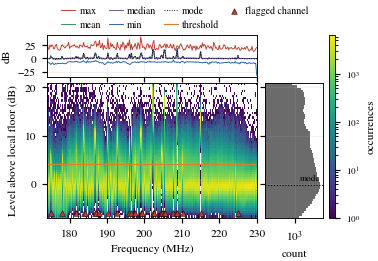

In [7]:
def heatmap_product(Mx, uf, fname, ylabel, ridge_line=None, thr=None, cmap='magma', flag=None, vmin=None):
    import matplotlib.patheffects as pe
    Lx = Mx[np.isfinite(Mx)]
    w = quantized_bin_width(Lx)
    lo, hi = np.floor(np.percentile(Lx, 0.05)), np.ceil(np.percentile(Lx, 99.99))
    ledges = np.arange(lo, hi + 0.5, 0.5)
    step = np.median(np.diff(uf))
    fedges = np.concatenate([uf - step / 2, [uf[-1] + step / 2]])
    ff = np.repeat(uf[None, :], Mx.shape[0], 0)
    m = np.isfinite(Mx)
    H, _, _ = np.histogram2d(ff[m], Mx[m], bins=[fedges, ledges])
    fig = plt.figure(figsize=(COL, 2.16))
    gs = GridSpec(2, 2, width_ratios=[4, 1.1], height_ratios=[1, 3.2], hspace=0.06, wspace=0.06)
    ax_top = fig.add_subplot(gs[0, 0]); ax = fig.add_subplot(gs[1, 0], sharex=ax_top); ax_r = fig.add_subplot(gs[1, 1], sharey=ax)
    Hm = np.ma.masked_where(H.T == 0, H.T)
    pcm = ax.pcolormesh(fedges, ledges, Hm, norm=LogNorm(vmin=1, vmax=H.max()), cmap=cmap, rasterized=True)
    ax.set_xlabel('Frequency (MHz)'); ax.set_ylabel(ylabel)
    ax.set_xlim(uf[0] - step / 2, uf[-1] + step / 2); ax.set_ylim(lo, hi)
    if ridge_line is not None:
        ax.plot(uf, ridge_line, color='w', lw=0.7, ls='--', label='noise ridge $r(f)$', path_effects=[pe.Stroke(linewidth=1.6, foreground='k'), pe.Normal()])
    if thr is not None:
        ax.axhline(thr, color=C['orange'], lw=0.8, ls='-', label='threshold')
    if flag is not None:
        ax.scatter(flag, [lo + 1.0] * len(flag), marker='^', s=14, color=C['red'], edgecolor='k', linewidth=0.3, label='flagged channel', zorder=10)
    cmin = np.nanmin(Mx, 0); cmax = np.nanmax(Mx, 0); cmed = np.nanmedian(Mx, 0); cmean = np.nanmean(Mx, 0)
    ax_top.plot(uf, cmax, color=C['red'], lw=0.6, label='max'); ax_top.plot(uf, cmean, color=C['green'], lw=0.6, label='mean')
    ax_top.plot(uf, cmed, color=C['purple'], lw=0.6, label='median'); ax_top.plot(uf, cmin, color=C['blue'], lw=0.6, label='min')
    cmode = np.array([ledges[:-1][np.argmax(H[j])] + 0.25 for j in range(H.shape[0])])
    ax_top.plot(uf, cmode, color='k', lw=0.6, ls=':', label='mode')
    ax_top.set_ylabel('dB'); ax_top.grid(alpha=0.25, lw=0.4); plt.setp(ax_top.get_xticklabels(), visible=False)
    ctr, cnt, _ = histogram_q(Lx, 0.5)
    ax_r.barh(ctr, cnt, height=0.5, color=C['gray'])
    ax_r.axhline(ctr[np.argmax(cnt)], color='k', lw=0.7, ls=':'); ax_r.text(0.95, ctr[np.argmax(cnt)] + 0.6, 'mode', ha='right', va='bottom', fontsize=6, transform=ax_r.get_yaxis_transform())
    ax_r.set_xscale('log'); ax_r.set_xlabel('count'); plt.setp(ax_r.get_yticklabels(), visible=False); ax_r.grid(alpha=0.25, lw=0.4)
    cb = fig.colorbar(pcm, ax=[ax_top, ax, ax_r], pad=0.02, fraction=0.04, aspect=30)
    cb.set_label('occurrences'); cb.ax.tick_params(labelsize=6)
    # one legend row above the panels (outside the data area): statistics of the top panel + overlays of the heatmap
    h1, l1 = ax_top.get_legend_handles_labels(); h2, l2 = ax.get_legend_handles_labels()
    nl = len(h1) + len(h2); x0 = ax_top.get_position().x0; x1 = ax_r.get_position().x1
    fig.legend(h1 + h2, l1 + l2, ncol=nl if nl <= 6 else (nl + 1) // 2, loc='lower center', bbox_to_anchor=((x0 + x1) / 2, ax_top.get_position().y1),
               bbox_transform=fig.transFigure, frameon=False, handlelength=1.4, handletextpad=0.4, columnspacing=0.8, borderaxespad=0.1)
    save(fig, fname)
    plt.show()


heatmap_product(M, uf, 'fig2_heatmap_raw', 'Level (dBµV/m)', ridge_line=ridge)
flagged = [r['f'] for r in R['flagged']]
heatmap_product(E, uf, 'supp_heatmap_detrended', 'Level above local floor (dB)', thr=R['E']['T_used'], flag=flagged, cmap='viridis')

## 8. Fig. 3 — band level histograms with the log-χ² fit, competing models and analytic thresholds

saved fig3_hist_fits


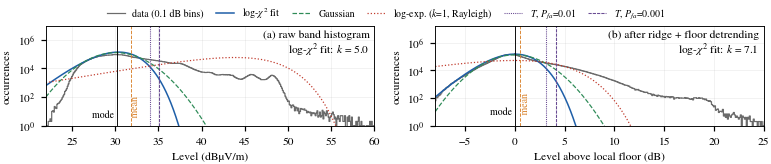

In [8]:
def model_curves(x, fitres, n, w):
    return n * w * np.exp(lg_logpdf(x, fitres['mu'], fitres['k']))

L = M[np.isfinite(M)]; Ld = D[np.isfinite(D)]; Le = E[:, good]; Le = Le[np.isfinite(Le)]
fig, axs = plt.subplots(1, 2, figsize=(COL * 2 + 0.3, 1.46))
for ax, x, title, key, xlab in [(axs[0], L, '(a) raw band histogram', 'raw', 'Level (dBµV/m)'),
                                 (axs[1], Le, '(b) after ridge + floor detrending', 'E', 'Level above local floor (dB)')]:
    w = 0.1
    ctr, cnt, _ = histogram_q(x, w)
    fit = fit_loggamma(x, TRUNC_DB, w=w)
    n = cnt.sum()
    ax.step(ctr, cnt, where='mid', color=C['gray'], lw=0.8, label='data (0.1 dB bins)')
    xx = np.linspace(ctr[0], ctr[-1], 1500)
    ax.plot(xx, model_curves(xx, fit, n, w), color=C['blue'], lw=1.0, label='log-$\\chi^2$ fit')
    g = fit_model(x, gauss_cdf, [fit['mode_hist'], 1.0], w=w)
    ax.plot(xx, n * w * stats.norm.pdf(xx, *g['params']), color=C['green'], lw=0.8, ls='--', label='Gaussian')
    k1 = fit_model(x, lambda v, mu, d: lg_cdf(v, mu, 1.0), [fit['mode_hist'], 1.0], w=w)
    ax.plot(xx, n * w * np.exp(lg_logpdf(xx, k1['params'][0], 1.0)), color=C['red'], lw=0.8, ls=':', label='log-exp. ($k$=1, Rayleigh)')
    ax.axvline(fit['mode_hist'], color='k', lw=0.6, ls='-'); ax.axvline(x.mean(), color=C['orange'], lw=0.6, ls='--')
    ax.text(fit['mode_hist'], cnt.max() * 1e-5 * 3, 'mode ', fontsize=6.5, va='bottom', ha='right')
    ax.text(x.mean(), cnt.max() * 1e-5 * 3, ' mean', fontsize=6.5, va='bottom', ha='left', rotation=90, color=C['orange'])
    for pfa, ls in [(1e-2, (0, (1, 1))), (1e-3, (0, (3, 1)))]:
        T = lg_threshold(fit['mu'], fit['k'], pfa)
        ax.axvline(T, color=C['purple'], lw=0.7, ls=ls, label=f'$T$, $P_{{fa}}$={pfa:g}')
    ax.set_yscale('log'); ax.set_ylim(max(1, cnt.max() * 1e-6), cnt.max() * 100)   # headroom for the panel tag
    if key == 'raw': ax.set_xlim(22, 60)
    else: ax.set_xlim(-8, 25)
    ax.set_xlabel(xlab); ax.set_ylabel('occurrences')
    ax.text(0.985, 0.96, f'{title}\nlog-$\\chi^2$ fit: $k$ = {fit["k"]:.1f}', transform=ax.transAxes, ha='right', va='top', fontsize=7.5, linespacing=1.15)
    ax.grid(alpha=0.25, lw=0.4)
fig.tight_layout(w_pad=1.0); hh, ll = axs[0].get_legend_handles_labels()
fig.legend(hh, ll, ncol=len(hh), loc='lower center', bbox_to_anchor=(0.5, axs[0].get_position().y1), bbox_transform=fig.transFigure, frameon=False, handlelength=1.8, columnspacing=1.2, borderaxespad=0.1)
save(fig, 'fig3_hist_fits'); plt.show()



## 9. Supplementary — column histogram-max levels and the interpolated noise ridge (not in the conference paper)

saved supp_ridge


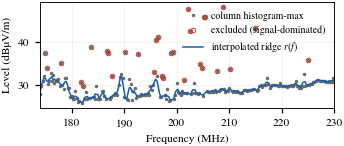

In [9]:
fig, ax = plt.subplots(figsize=(COL, 1.25))
ax.plot(uf, modes, '.', ms=2.5, color=C['gray'], label='column histogram-max')
ax.plot(uf[~good], modes[~good], 'o', ms=3, mfc='none', mec=C['red'], mew=0.6, label='excluded (signal-dominated)')
ax.plot(uf, ridge, color=C['blue'], lw=1.0, label='interpolated ridge $r(f)$')
ax.set_xlabel('Frequency (MHz)'); ax.set_ylabel('Level (dBµV/m)'); ax.grid(alpha=0.25, lw=0.4)
ax.legend(frameon=False, loc='upper right', ncol=1); ax.set_xlim(uf[0], uf[-1])
save(fig, 'supp_ridge'); plt.show()



## 10. Fig. 4 — diurnal band floor at the three stations and empirical vs. model tail

saved fig4_floor_tail


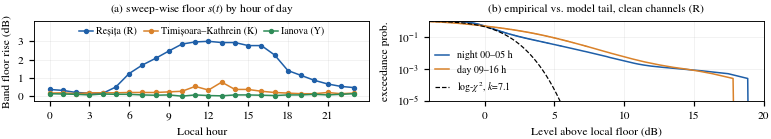

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(COL * 2 + 0.3, 1.45))
ax = axs[0]
for (tag, (_, _, lab)), c in zip(STATIONS.items(), [C['blue'], C['orange'], C['green']]):
    ax.plot(range(24), res[tag]['floor_by_hour'], '-o', ms=2.5, color=c, label=lab)
ax.set_xlabel('Local hour'); ax.set_ylabel('Band floor rise (dB)'); ax.set_xticks(range(0, 24, 3)); ax.grid(alpha=0.25, lw=0.4)
ax.set_ylim(-0.25, 4.1); ax.set_yticks([0, 1, 2, 3])
ax.legend(frameon=False, ncol=3, loc='upper center', handlelength=1.4, handletextpad=0.3, columnspacing=0.7, borderaxespad=0.15)
ax.set_title('(a) sweep-wise floor $s(t)$ by hour of day', fontsize=7.5)
ax = axs[1]
hrs = t.hour
for m, lab, c in [(hrs <= 5, 'night 00–05 h', C['blue']), ((hrs >= 9) & (hrs <= 16), 'day 09–16 h', C['orange'])]:
    x = E[m][:, good]; x = x[np.isfinite(x)]
    xs = np.sort(x); sfun = 1 - np.arange(1, xs.size + 1) / xs.size
    sel = np.linspace(0, xs.size - 1, 4000).astype(int)
    ax.plot(xs[sel], sfun[sel], color=c, lw=1.0, label=lab)
Le = E[:, good]; Le = Le[np.isfinite(Le)]
fe = fit_loggamma(Le, TRUNC_DB, w=quantized_bin_width(Le))
xx = np.linspace(-4, 20, 500)
ax.plot(xx, lg_sf(xx, fe['mu'], fe['k']), color='k', lw=0.8, ls='--', label=f'log-$\\chi^2$, $k$={fe["k"]:.1f}')
ax.set_yscale('log'); ax.set_ylim(1e-5, 1); ax.set_xlim(-4, 20)
ax.set_xlabel('Level above local floor (dB)'); ax.set_ylabel('exceedance prob.'); ax.grid(alpha=0.25, lw=0.4)
ax.legend(frameon=False, loc='lower left', handlelength=1.4, borderaxespad=0.2); ax.set_title('(b) empirical vs. model tail, clean channels (' + MAIN + ')', fontsize=7.5)
fig.tight_layout(w_pad=1.0); save(fig, 'fig4_floor_tail'); plt.show()



## 11. Supplementary — FM-band record and detected transmitters (not in the conference paper)

saved supp_fm_record


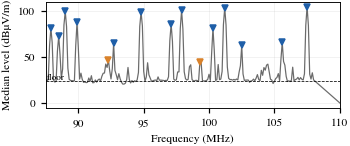

In [11]:
med = np.nanmedian(Mf, 0)
fig, ax = plt.subplots(figsize=(COL, 1.25))
ax.plot(uff, med, color=C['gray'], lw=0.8)
for f, l in R['fm']['tx20']:
    ax.plot(f, l, 'v', color=C['blue'] if l > R['fm']['floor'] + 35 else C['orange'], ms=3.5)
ax.axhline(R['fm']['floor'], color='k', lw=0.5, ls='--'); ax.text(87.6, R['fm']['floor'] + 1, 'floor', fontsize=6)
ax.set_xlim(uff[0], uff[-1]); ax.set_xlabel('Frequency (MHz)'); ax.set_ylabel('Median level (dBµV/m)'); ax.grid(alpha=0.25, lw=0.4)
save(fig, 'supp_fm_record'); plt.show()



## 12. Fig. 5 — per-channel features and classes; co-activation of FM-product channels

saved fig5_classification


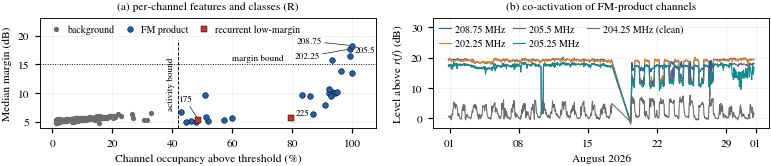

In [12]:
rows = R['flagged']
marg = np.zeros(len(uf));
Tu = R['E']['T_used']
for j in range(len(uf)):
    e = E[:, j]; e = e[np.isfinite(e) & (e > Tu)]
    marg[j] = np.median(e) if e.size else 0
fig, axs = plt.subplots(1, 2, figsize=(COL * 2 + 0.3, 1.7))
ax = axs[0]
ax.scatter(occ * 100, marg, s=6, color=C['gray'], label='background', zorder=1)
fl = {r['f']: r for r in rows}
for cls, c, mk in [('FM product', C['blue'], 'o'), ('recurrent low-margin', C['red'], 's'), ('signal', C['green'], '^')]:
    ff = [r['f'] for r in rows if r['cls'] == cls]
    if not ff: continue
    jj = [int(np.argmin(abs(uf - f))) for f in ff]
    ax.scatter(occ[jj] * 100, marg[jj], s=14, color=c, marker=mk, label=cls, zorder=3, edgecolor='k', linewidth=0.3)
ax.axvline(R['occ_bg']['activity_bound'] * 100, color='k', lw=0.6, ls='--', ymax=0.8); ax.text(R['occ_bg']['activity_bound'] * 100 - 1, 7.0, 'activity bound', fontsize=6, rotation=90, va='bottom', ha='right')
ax.axhline(15, color='k', lw=0.6, ls=':'); ax.text(60, 15.3, 'margin bound', fontsize=6, va='bottom')
ax.set_ylim(4, 23); ax.set_xlim(-4, 108)
OFF = {208.75: (-20, 3), 202.25: (-20, -5), 175.0: (-4, 13)}   # label offsets (points) that keep these labels clear of the markers
for f in sorted([r['f'] for r in rows], key=lambda f: -marg[int(np.argmin(abs(uf - f)))])[:3] + [r['f'] for r in rows if not r['matches']]:
    j = int(np.argmin(abs(uf - f))); dx, dy = OFF.get(f, (3, 2))
    ax.annotate(f'{f:g}', (occ[j] * 100, marg[j]), fontsize=6, xytext=(dx, dy), textcoords='offset points', ha='right' if dx < 0 else 'left', va='center' if dx < 0 else 'baseline',
                arrowprops=dict(arrowstyle='-', lw=0.4, color='k', shrinkA=0, shrinkB=2) if abs(dx) + abs(dy) > 12 else None)
ax.set_xlabel('Channel occupancy above threshold (%)'); ax.set_ylabel('Median margin (dB)')
ax.legend(frameon=False, ncol=3, loc='upper left', handletextpad=0.1, columnspacing=0.6, borderaxespad=0.2); ax.grid(alpha=0.25, lw=0.4); ax.set_title('(a) per-channel features and classes (' + MAIN + ')', fontsize=7.5)
ax = axs[1]
hour_id = t.values.astype('datetime64[h]'); uh = np.unique(hour_id)
def hm(j): return np.array([np.nanmedian(D[hour_id == h, j]) for h in uh])
top = sorted([r for r in rows if r['matches']], key=lambda r: -r['margin'])[:4]
sel = [(r['f'], c) for r, c in zip(top, [C['blue'], C['orange'], C['purple'], C['teal']])]
th = uh.astype('datetime64[us]')
for f, c in sel:
    j = int(np.argmin(abs(uf - f))); ax.plot(th, hm(j), lw=0.7, color=c, label=f'{f:g} MHz')
jc = np.flatnonzero(good)[100]; ax.plot(th, hm(jc), lw=0.7, color=C['gray'], label=f'{uf[jc]:g} MHz (clean)')
ax.set_ylabel('Level above $r(f)$ (dB)'); ax.set_xlabel(t[0].strftime('%B %Y'))
ax.xaxis.set_major_locator(matplotlib.dates.DayLocator(bymonthday=[1, 8, 15, 22, 29]))
ax.xaxis.set_major_formatter(matplotlib.dates.DateFormatter('%d'))
ax.legend(frameon=False, ncol=3, loc='upper left', handlelength=1.2, handletextpad=0.4, columnspacing=0.8, borderaxespad=0.2); ax.grid(alpha=0.25, lw=0.4); ax.set_ylim(-3, 33)
ax.set_title('(b) co-activation of FM-product channels', fontsize=7.5)
fig.tight_layout(w_pad=1.0); save(fig, 'fig5_classification'); plt.show()



## 13. Tables II–III, the noise-model comparison (supplementary) and the flagged-channel list

### How the goodness-of-fit statistics are computed (`gof_stats` in `pipeline.py`)

**Data.** The histogram of the band levels with the quantization-aware bin width of eq. (1) (0.1 dB for a full band), restricted to the *truncated noise region*: bins with centre ≤ μ₀ + 3 dB, where μ₀ is the histogram mode. Bins above that limit contain signals and receiver products and are excluded from both the fit and the test (for the main station this keeps ≈ 70 % of the samples, ≈ 5·10⁶).

**Fit.** Every candidate model — log-χ² (log-gamma), Gaussian in dB, Gumbel (minimum), log-exponential (k = 1) — is fitted by the same truncated, binned maximum likelihood: with model CDF F(x; θ), the bin probability is p_i(θ) = [F(hi_i) − F(lo_i)] / F(x_t + w/2), renormalised on the truncated region, and −Σ c_i ln p_i(θ) is minimised (Nelder–Mead), c_i being the observed counts. Each model has two parameters.

**Reduced chi-square.** Expected counts E_i = n·p_i; bins with E_i > 5 are kept; χ² = Σ (c_i − E_i)² / E_i and χ²_ν = χ² / ν with ν = (bins kept) − 2 − 1.

**Kolmogorov–Smirnov distance.** On the same bin edges, F_emp(x_i) = Σ_{j≤i} c_j / n and F_mod(x_i) = Σ_{j≤i} p_j; KS = max_i |F_emp − F_mod|. This is the discretised distance, not the KS test with a p-value.

**Interpretation.** With n ≈ 5·10⁶ the 5 % critical KS value is 1.36/√n ≈ 0.0006 and χ²_ν should be ≈ 1, so every two-parameter model is formally rejected: the statistics are used to *rank* the models, not to accept one. The ranking is the same under both statistics and in both regimes (raw band, ridge-detrended). Note that the test is in-sample (parameters and statistics come from the same region); out-of-sample behaviour is checked separately by the split-half validation on odd/even sweeps. The 3-dB truncation limit is a choice; the ranking is unchanged for 2–4 dB (`trunc_above_mode` in `fit_loggamma` / `fit_model`).

In [13]:
# Supplementary — noise-model comparison (numbers quoted in Sec. IV-A; table not in the conference paper)
tab2 = pd.DataFrame({('raw band', k): v for k, v in R['raw']['gof'].items()} | {('ridge-detrended', k): v for k, v in R['detr']['gof'].items()}).T[['KS', 'chi2_dof']]
tab2.to_csv(os.path.join(OUT_DIR, 'supp_gof.csv')); display(tab2.round(3))

# Table II — flagged channels
tab3 = pd.DataFrame(R['flagged']); tab3['matches'] = tab3['matches'].apply(lambda m: ', '.join(m))
tab3['occ'] = (100 * tab3['occ']).round(0)
tab3.to_csv(os.path.join(OUT_DIR, 'table2_flagged.csv'), index=False); display(tab3)

# Table III — occupancy (%) under competing threshold rules, all stations
tab4 = pd.DataFrame({tag: {k: 100 * v for k, v in res[tag]['occupancy_rules'].items()} for tag in STATIONS})
tab4.to_csv(os.path.join(OUT_DIR, 'table3_occupancy_rules.csv')); display(tab4.round(2))

# FM-arithmetic significance and co-activation
for tag in STATIONS:
    print(tag, 'arithmetic:', res[tag]['arith'], '| co-activation:', res[tag]['coact'])

KS   chi2_dof
raw band        log-chi2         0.034   1455.693
                Gaussian         0.020    707.834
                Gumbel           0.049   2273.410
                log-exponential  0.174   6470.941
ridge-detrended log-chi2         0.054   3723.926
                Gaussian         0.039   2492.963
                Gumbel           0.085   5848.878
                log-exponential  0.290  11736.985

,f,occ,margin,p95,days,matches,cls
0,175.00,49.0,5.400000,7.000000,31,,recurrent low-margin
1,178.00,52.0,5.100000,6.566667,31,"2x89.0, 87.9+89.9",FM product
2,181.75,51.0,5.900000,9.666667,31,89.0+92.7,FM product
3,183.75,93.0,10.233333,12.500000,31,89.0+94.8,FM product
4,184.00,43.0,6.733333,10.333333,31,89.0+94.8,FM product
5,186.75,86.0,9.500000,11.433333,31,"89.0+97.9, 89.9+97.1",FM product
6,187.00,92.0,9.933333,11.500000,31,"87.9+99.3, 89.0+97.9, 89.9+97.1, 92.3+94.8",FM product
7,187.75,48.0,5.000000,8.266667,31,"88.5+99.3, 89.9+97.9, 92.7+94.8",FM product
8,190.25,94.0,9.966667,11.500000,31,"87.9+102.5, 89.0+101.2, 89.9+100.3, 92.3+97.9",FM product
9,192.75,93.0,9.416667,11.616667,31,"92.3+100.3, 92.7+100.3, 94.8+97.9",FM product


,R,K,Y
fixed squelch 40 dBµV/m,4.13,100.00,99.99
band mean + 10 dB,2.86,2.06,0.03
band mode + 10 dB,3.97,2.61,0.03
band mode + 6 dB,12.83,5.71,0.06
"log-chi2 T(1e-3), raw band",17.42,9.05,0.91
"log-chi2 T(1e-3), ridge-detrended",30.67,9.83,1.27
"log-chi2 T(1e-3), ridge + floor",18.32,7.94,1.18
"empirical 99th pct, ridge + floor",6.00,1.00,1.00


R arithmetic: {'physical': {'n_products': 108, 'n_touched': 132, 'frac_touched': 0.5866666666666667, 'n_matched': 25, 'p': 4.709915190831146e-05}, 'strict': {'n_products': 108, 'n_touched': 84, 'frac_touched': 0.37333333333333335, 'n_matched': 18, 'p': 0.0009823102528936226}} | co-activation: {'fm_products': 0.6193521745655145, 'clean': 0.02390405818631025, 'n_fm': 25}
K arithmetic: {'physical': {'n_products': 143, 'n_touched': 132, 'frac_touched': 0.5866666666666667, 'n_matched': 0, 'p': None}, 'strict': {'n_products': 143, 'n_touched': 103, 'frac_touched': 0.4577777777777778, 'n_matched': 0, 'p': None}} | co-activation: {'fm_products': None, 'clean': 0.07236025916450328, 'n_fm': 0}
Y arithmetic: {'physical': {'n_products': 86, 'n_touched': 109, 'frac_touched': 0.48444444444444446, 'n_matched': 0, 'p': 1.0}, 'strict': {'n_products': 86, 'n_touched': 69, 'frac_touched': 0.30666666666666664, 'n_matched': 0, 'p': 1.0}} | co-activation: {'fm_products': None, 'clean': 0.0423451691589332, '

## 14. Key numbers quoted in the paper (main station)

In [14]:
print(f"Raw histogram: FD width {R['raw']['fd_width']:.3f} dB -> bin {R['raw']['w']:.1f} dB; mode {R['raw']['mode']:.1f}, median {R['raw']['median']:.1f}, mean {R['raw']['mean']:.1f} dBµV/m")
print(f"Log-chi2 fit (raw): mu={R['raw']['mu']:.2f}, k={R['raw']['k']:.1f}, sigma={R['raw']['sigma']:.2f} dB; T(1e-3)={R['raw']['T']['0.001']:.2f} dBµV/m")
print(f"Ridge: column modes {R['ridge']['modes_min']:.1f}-{R['ridge']['modes_max']:.1f}, ridge {R['ridge']['min']:.1f}-{R['ridge']['max']:.1f} dBµV/m, {R['ridge']['n_excluded']} columns excluded")
print(f"FWHM of the noise mode: raw {R['raw']['fwhm']:.1f} dB -> ridge-detrended {R['detr']['fwhm']:.1f} dB; k {R['raw']['k']:.1f} -> {R['detr']['k']:.1f}")
print(f"Thresholds above local floor (ridge-detrended): " + ', '.join(f"T({p})={v:.2f}" for p, v in R['detr']['T'].items()))
print(f"Diurnal floor rise: night {min(R['floor_by_hour'][:6]):.2f} dB, midday {max(R['floor_by_hour']):.2f} dB")
print(f"Ridge+floor detrended: k={R['E']['k']:.1f}, T(Pfa)={R['E']['T_used']:.2f} dB; realised exceedance {100*R['E']['tail'][str(PFA)]:.1f} % "
      f"(night {100*R['E']['tail_night'][str(PFA)]:.1f} %, day {100*R['E']['tail_day'][str(PFA)]:.1f} %); 99th/99.9th pct {R['E']['quantiles']['99']:.1f}/{R['E']['quantiles']['99.9']:.1f} dB")
print('Split-half:', json.dumps(R['splithalf'], indent=1))
print(f"FM: {len(R['fm']['tx20'])} transmitters >= floor+20 dB, {len(R['fm']['tx35'])} >= floor+35 dB; floor {R['fm']['floor']:.1f} dBµV/m")
print(f"Background occupancy: median {100*R['occ_bg']['median']:.1f} %, MAD {100*R['occ_bg']['mad']:.1f} %, activity bound {100*R['occ_bg']['activity_bound']:.1f} %")
print(f"Flagged {len(R['flagged'])} channels: {R['classes']}")

Raw histogram: FD width 0.050 dB -> bin 0.1 dB; mode 30.2, median 31.0, mean 31.8 dBµV/m
Log-chi2 fit (raw): mu=30.39, k=5.0, sigma=2.05 dB; T(1e-3)=35.11 dBµV/m
Ridge: column modes 25.8-48.2, ridge 26.0-32.1 dBµV/m, 30 columns excluded
FWHM of the noise mode: raw 6.2 dB -> ridge-detrended 2.9 dB; k 5.0 -> 11.4
Thresholds above local floor (ridge-detrended): T(0.01)=3.21, T(0.001)=3.98, T(0.0001)=4.58
Diurnal floor rise: night 0.15 dB, midday 3.00 dB
Ridge+floor detrended: k=7.1, T(Pfa)=4.09 dB; realised exceedance 10.4 % (night 5.1 %, day 13.5 %); 99th/99.9th pct 8.8/14.2 dB
Split-half: {
 "odd->even": {
  "k": 7.087482802234345,
  "T": 4.095809249932592,
  "exceed": 0.10395001127700243,
  "emp99_T": 8.850000000000001,
  "emp99_exceed": 0.009879519034182957
 },
 "even->odd": {
  "k": 7.0978603205655375,
  "T": 4.093366538588097,
  "exceed": 0.10418689754401723,
  "emp99_T": 8.833333333333321,
  "emp99_exceed": 0.010129993263304972
 }
}
FM: 15 transmitters >= floor+20 dB, 13 >= floor+3